In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
from datetime import datetime

import sys
sys.path.append("../../tools")
import prepare as prep
import functions as func
import generation as gr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [6]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


In [7]:
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
nmodel = func.load_saved_model_NS(load_dir3, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
npredictor = func.Predictor(nmodel)
MaxNum = emodel["NumSpecies"]


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


**Entropy & Diversity**

In [3]:
df = pd.read_pickle("efficient_raise_H_sp10_v6.pkl")


In [ ]:
n_real = 10
featgam = n_real**2 - n_real
MaxNum = 20
task_num = 1

compare = []
for idx in range(df.shape[0]):

    df_sample = df.iloc[idx, :]
    n = len(df_sample["y_list"])
    select_idx = np.linspace(0, n - 1, 3, dtype=int)

    select_idx = np.unique(select_idx)

    selected_X_list = [
        df_sample["X_list"][i]
        for i in select_idx
    ]
    selected_y_list = [
        df_sample["y_list"][i]
        for i in select_idx
    ]
    fin_Xnum_pad = np.stack(selected_X_list) 
    ini_Xnum_pad = df_sample["initial_X"] 

    ini_Xnum = prep.recovery_Xnum(ini_Xnum_pad, n_real, MaxNum)
    fin_Xnum = prep.recovery_Xnum(fin_Xnum_pad, n_real, MaxNum)
    ini_Xynum = gr.predict_numerical(ini_Xnum, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
    fin_Xynum = gr.predict_numerical(fin_Xnum, n_real, repeat=200, timespan=np.arange(0,800.1,.1))

    for i, original_i in enumerate(select_idx):

        compare.append({
            "sample_idx": idx,
            "initial_X": df_sample["initial_X"],
            "pre_ini_y": df_sample["initial_y"],
            "real_ini_y": ini_Xynum[0, n_real + featgam + n_real + task_num],
            "final_X": selected_X_list[i],
            "pre_fin_y": selected_y_list[i],
            "real_fin_y": fin_Xynum[i, n_real + featgam + n_real + task_num],
        })

df_compare = pd.DataFrame(compare)
df_compare.to_pickle(f"efficient_raise_vali_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pkl")


**Number of stable states**

In [2]:
df = pd.read_pickle("efficient_raise_N_vali_20261108_034742.pkl")


In [ ]:
n_real = 10
featgam = n_real**2 - n_real
MaxNum = 20
task_num = 0

compare = []
for idx in range(df.shape[0]):
#for idx in range(1):

    df_sample = df.iloc[idx, :]
    ini_Xnum_pad = df_sample["initial_X"]
    fin_Xnum_pad = df_sample["final_X"]

    pre_ini_N = npredictor.predict_array_NS(ini_Xnum_pad, device).item()
    pre_fin_N = npredictor.predict_array_NS(fin_Xnum_pad, device).item()

    ini_Xnum = prep.recovery_Xnum(ini_Xnum_pad, n_real, MaxNum)
    fin_Xnum = prep.recovery_Xnum(fin_Xnum_pad, n_real, MaxNum)
    ini_Xynum = gr.predict_numerical(ini_Xnum, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
    fin_Xynum = gr.predict_numerical(fin_Xnum, n_real, repeat=200, timespan=np.arange(0,800.1,.1))

    compare.append({
        "sample_idx": idx,
        "initial_X": df_sample["initial_X"],
        "pre_ini_y": pre_ini_N,
        "real_ini_y": ini_Xynum[0, n_real + featgam + n_real + task_num],
        "final_X": df_sample["final_X"],
        "pre_fin_y": pre_fin_N,
        "real_fin_y": fin_Xynum[0, n_real + featgam + n_real + task_num],
    })

df_compare = pd.DataFrame(compare)
df_compare.to_pickle(f"efficient_raise_N_vali_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pkl")


In [7]:
from scipy.stats import spearmanr
from sklearn.metrics import r2_score
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

df_compare = pd.read_pickle("efficient_N_vali.pkl")


In [5]:
Xnum1 = df_compare["initial_X"].iloc[1].reshape(1, -1)
Xnum2 = df_compare["final_X"].iloc[1].reshape(1, -1)
Xnum_compare = np.concatenate([Xnum1, Xnum2], axis=0)


Spearman's rho: 0.5621600159489901
Pearson's r: 0.5131299070047061
r2: -0.5534090289894062


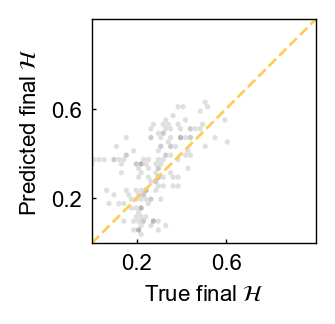

In [ ]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

cmap = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#f3f3f3", "#2E2626"]
)

plotx = df_compare["real_fin_y"].values
ploty = df_compare["pre_fin_y"].values

plt.figure(figsize=(1.4,1.4), dpi=200)

hb = plt.hexbin(
    plotx,
    ploty,
    gridsize=50, 
    extent=(0, 1.1, 0, 1.1),   # xmin, xmax, ymin, ymax
    mincnt=1, 
    cmap=cmap,
    vmin=0,
    vmax=10, 
    edgecolors='none',
    alpha=1,
    rasterized=True
)

plt.plot(
    [0, 1.1],
    [0, 1.1],
    linestyle='--',
    linewidth=1,
    color="#ffcb5b",
    zorder=2
)

spear=spearmanr(plotx, ploty).correlation 
pear=np.corrcoef(plotx, ploty)[0, 1] 
r2=r2_score(plotx, ploty)
print(f"Spearman's rho: {spear}")
print(f"Pearson's r: {pear}")
print(f"r2: {r2}")

# cbar = plt.colorbar(hb)
# cbar.set_label("Count")

ticks = [0.2, 0.6]
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xticks(ticks)
plt.yticks(ticks)
plt.xlabel(r"True final $\mathcal{H}$")
plt.ylabel(r"Predicted final $\mathcal{H}$")
plt.tick_params(direction='in')

plt.subplots_adjust(
    left=0.18,
    right=0.98,
    bottom=0.18,
    top=0.98
)

plt.savefig(f"efficient_vali_raise_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight', transparent=True,)
plt.show()


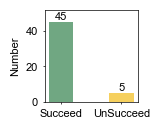

In [14]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'axes.linewidth': 0.5,
    'legend.fontsize': 7,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5,
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})


def plot_success_bar(
    succeed=45,
    unsuccess=5,
    colors=('#70A782', '#F6D05E'),
    figsize=(1.2, 1.2),
    ylabel='Number',
    save_path=None
):
    fig, ax = plt.subplots(figsize=figsize)

    values = [succeed, unsuccess]
    labels = ['Succeed', 'UnSucceed']
    x = np.arange(2)

    # Draw bars without outlines
    bars = ax.bar(
        x, values,
        width=0.4,
        color=colors,
        edgecolor='none',
        linewidth=0,
        zorder=3
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)

    ax.set_ylim(0, max(values) * 1.15)

    ax.tick_params(direction='out')

    # Keep all four spines
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color('black')

    # Add value labels
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(value),
            ha='center',
            va='bottom',
            fontsize=8
        )

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()


# Example
plot_success_bar(
    succeed=45,
    unsuccess=5,
    ylabel='Number',
    save_path="success_bar.pdf"
)


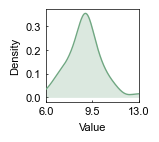

In [27]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

def plot_distribution(
    data,
    color='#70A782',
    figsize=(1.2, 1.2),
    xlabel='Value',
    ylabel='Density',
    show_kde=True,
    fill_alpha=0.25,
    save_path=None
):
    """
    Plot a KDE distribution with shaded area.
    """

    data = np.asarray(data).ravel()
    data = data[np.isfinite(data)]

    if len(data) < 2 or np.std(data) == 0:
        raise ValueError("At least two non-identical data points are required.")

    fig, ax = plt.subplots(figsize=figsize)

    if show_kde:
        kde = gaussian_kde(data)

        x_grid = np.linspace(data.min(), data.max(), 300)
        y_grid = kde(x_grid)

        ax.fill_between(
            x_grid, 0, y_grid,
            color=color,
            alpha=fill_alpha,
            linewidth=0,
            zorder=2
        )

        ax.plot(
            x_grid, y_grid,
            color=color,
            linewidth=1.0,
            zorder=3
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # Set x-axis ticks to minimum, midpoint, and maximum
    x_min = data.min()
    x_max = data.max()
    x_mid = (x_min + x_max) / 2

    ax.set_xlim(x_min, x_max)
    ax.set_xticks([x_min, x_mid, x_max])

    # Keep all four spines
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color('black')

    # Set ticks inward
    ax.tick_params(
        direction='in',
        width=0.5,
        length=1.5
    )

    if save_path is not None:
        plt.savefig(save_path, dpi=1000, bbox_inches='tight')

    plt.show()
    
df1 = pd.read_pickle("efficient_N1.pkl")
df2 = pd.read_pickle("efficient_N_vali.pkl")
df2_suc = df2[df2["real_fin_y"]==1]
index = df2_suc["sample_idx"].values
df1_suc = df1.loc[index, :]

data = df1_suc["paranum"].values
#data = np.random.normal(0.5, 0.15, 1000)

plot_distribution(
    data,
    color='#70A782',
    xlabel='Value',
    ylabel='Density',
    fill_alpha=0.25,
    save_path="distribution_parameter.pdf"
)
